Loaded: ETTm1.csv | shape: (69680, 8)
                 date   HUFL   HULL   MUFL   MULL   LUFL   LULL         OT
0 2016-07-01 00:00:00  5.827  2.009  1.599  0.462  4.203  1.340  30.531000
1 2016-07-01 00:15:00  5.760  2.076  1.492  0.426  4.264  1.401  30.459999
2 2016-07-01 00:30:00  5.760  1.942  1.492  0.391  4.234  1.310  30.038000
3 2016-07-01 00:45:00  5.760  1.942  1.492  0.426  4.234  1.310  27.013000
4 2016-07-01 01:00:00  5.693  2.076  1.492  0.426  4.142  1.371  27.787001
Missing values: 0 | duplicate timestamps: 0
{'train': '73 blocks = 49056 rows', 'val': '10 blocks = 6720 rows', 'test': '20 blocks = 13440 rows'}
Set-point (comfort) = 18.57 C | Hard limit = 25.04 C  (from TRAIN percentiles)
Static feature matrix: (69680, 10)
train: OT mean  13.4 | max  46.0 | % above set-point 24.8
val  : OT mean  14.3 | max  45.7 | % above set-point 29.1
test : OT mean  12.6 | max  39.4 | % above set-point 16.7


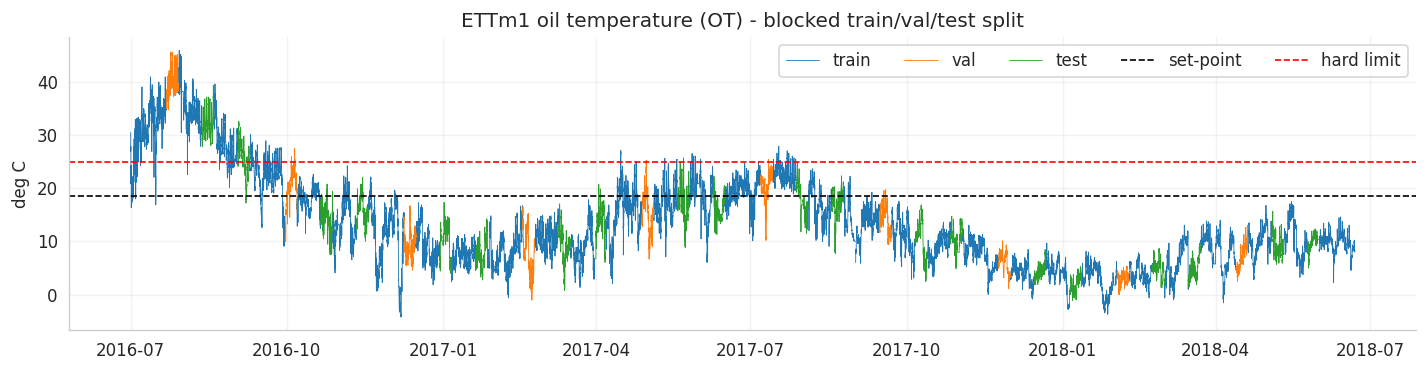

obs shape: (14,) | one random step: (-0.18000000000000002, False)
BASELINES on the TEST set
                 Total reward  Reward/step  Mean temp (C)  Max temp (C)  % time > set-point  % time > limit  Mean overshoot (C)  Avg cooling level  Cooling energy (stage-hours)  Level switches
No cooling          -3238.453       -0.241         12.646        39.394              16.662           8.003               1.137              0.000                          0.00             0.0
Always medium       -2282.380       -0.170          6.682        33.394               8.316           3.480               0.468              2.000                       6710.00             0.0
Always high         -2419.746       -0.180          3.700        30.394               6.215           1.051               0.252              3.000                      10065.00             0.0
Random              -2503.655       -0.187          8.162        35.513               9.463           4.449               0.589         

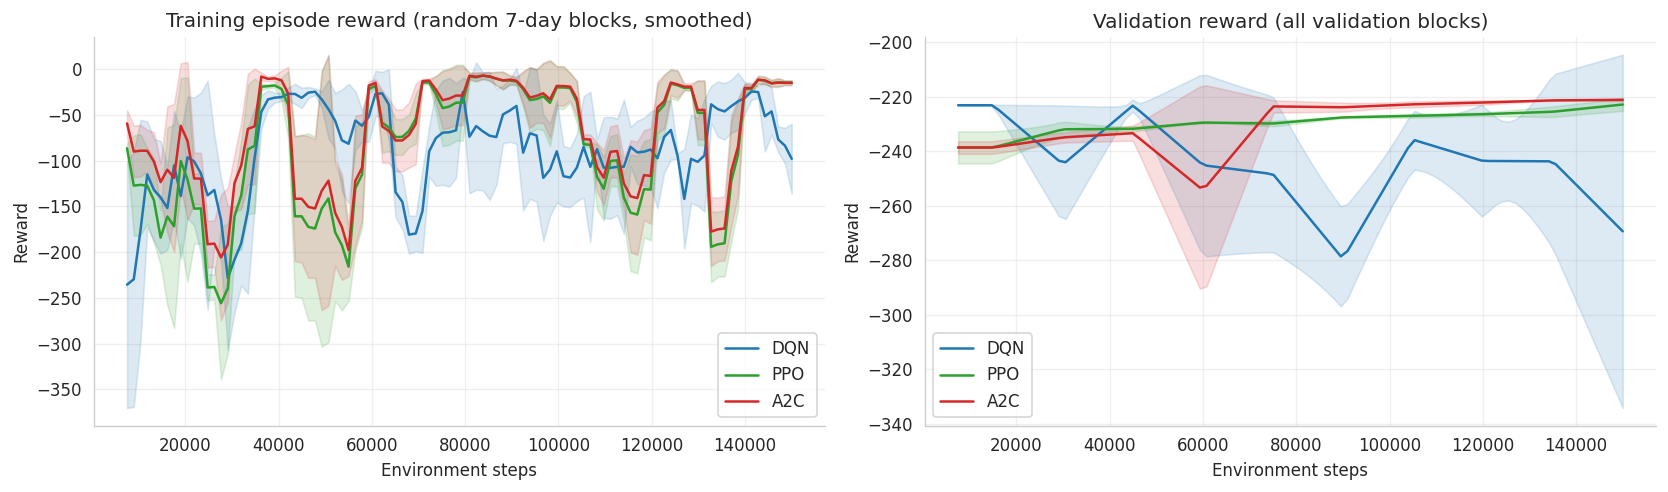

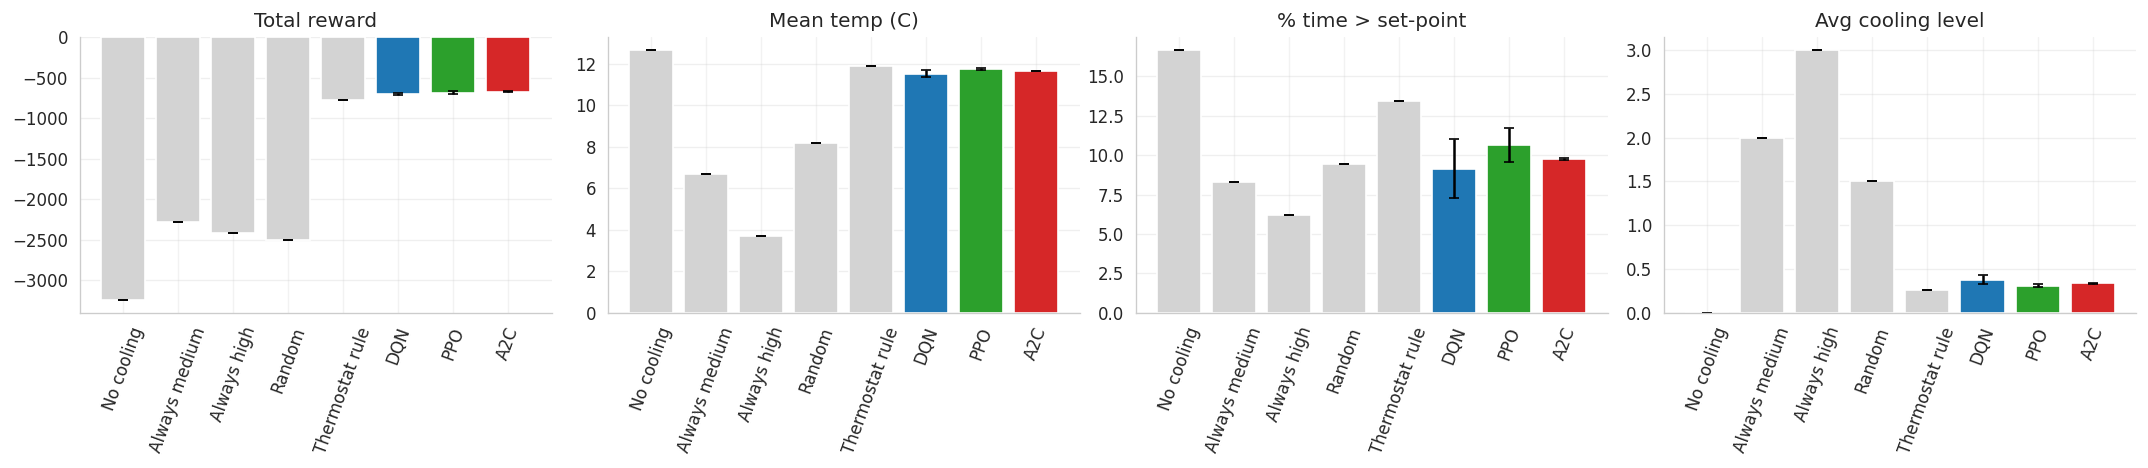

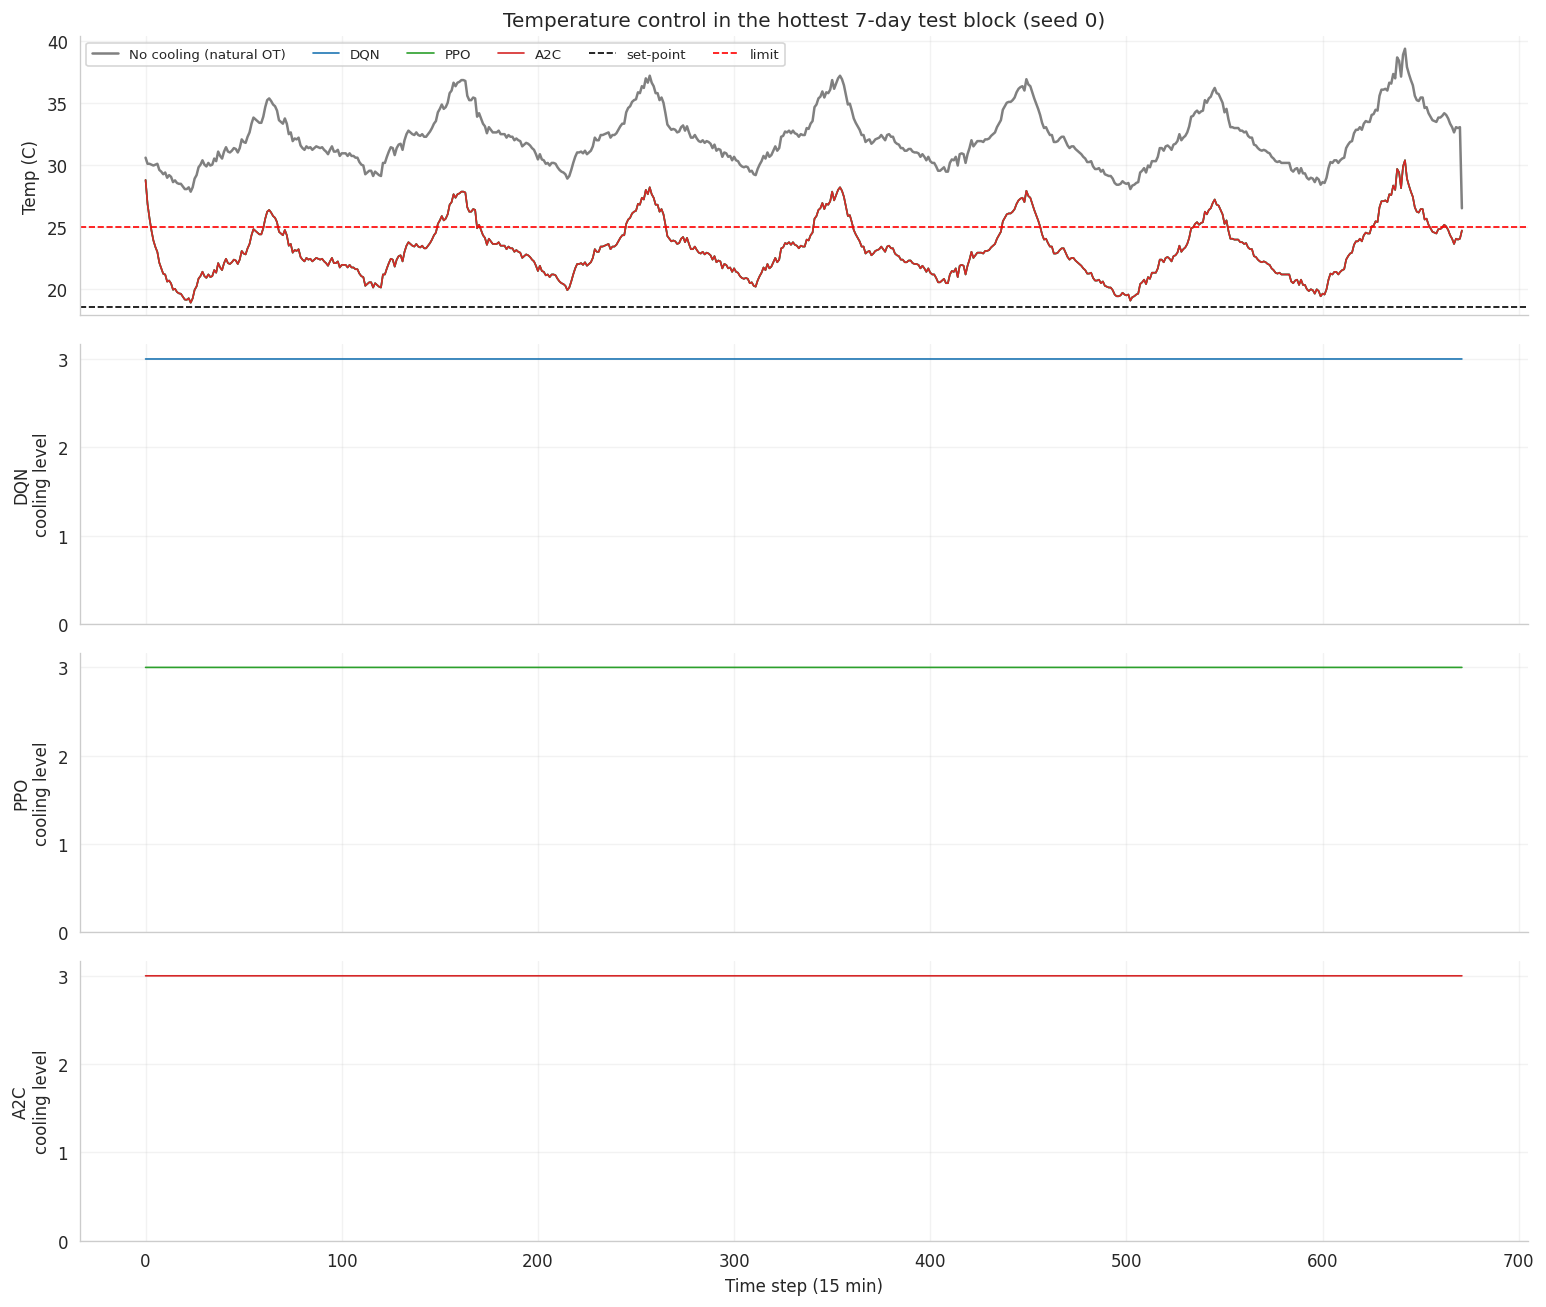

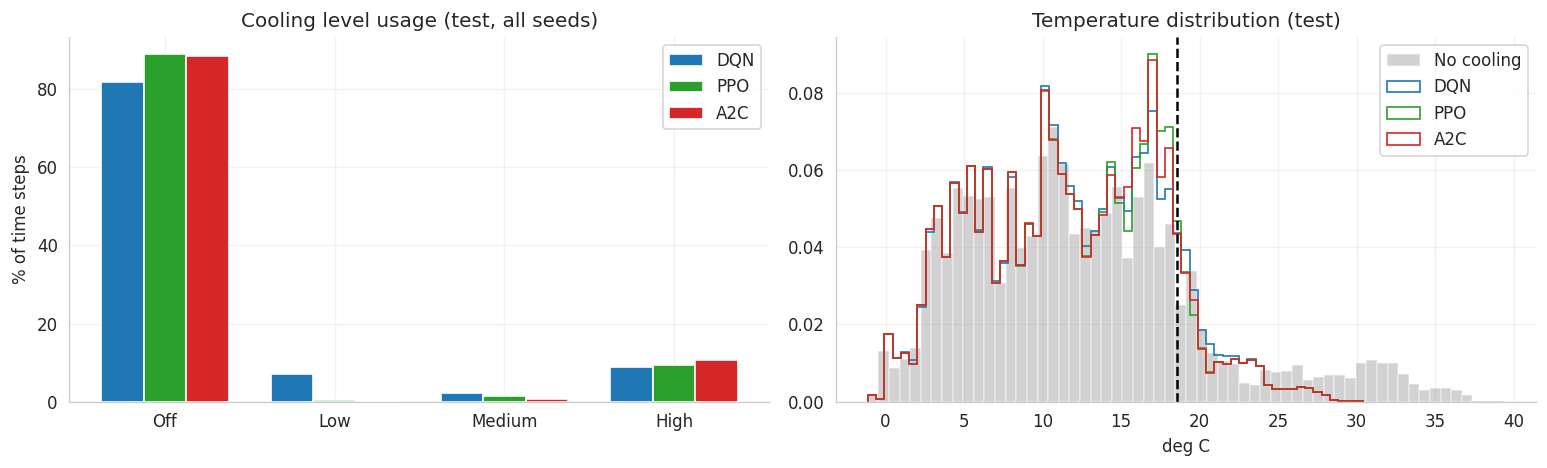

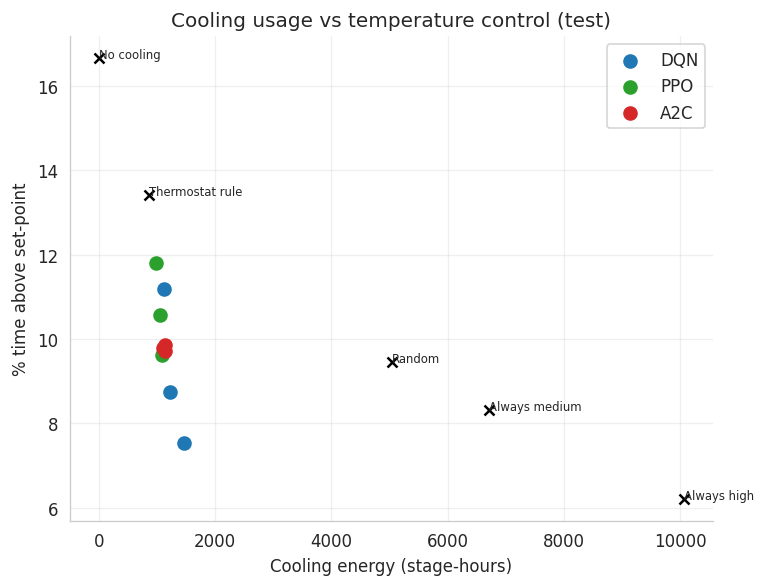

Ranking by mean test total reward:
Model
A2C   -671.90
PPO   -684.19
DQN   -704.83

Best RL model: A2C  (margin over PPO: 12.29; larger seed std of the two: 22.09)
-> The difference is WITHIN seed noise, so the ranking is NOT clearly reliable; run more seeds/steps.

Best model per criterion:
  Lowest mean temp (C): DQN
  Least time above set-point: DQN
  Least cooling energy: PPO
  Fewest level switches: A2C
  Most stable (lowest cross-seed test-reward std): A2C
  Least noisy late training: DQN
  Fastest training: A2C

Best baseline: Thermostat rule (total reward -775.77) vs best RL A2C (-671.90).
Reminder: results come from a SIMULATED cooling system built on real ETTm1 load/temperature data; ETTm1 has no real cooling-action data, so they must not be read as real-transformer performance.


In [14]:
# %% [markdown]
# # Comparative Analysis of RL Models for Transformer Cooling Control
# **Models:** DQN vs PPO vs A2C  |  **Data:** ETTm1 (69,680 rows, 15-min sampling)
#
# ## IMPORTANT: the cooling behaviour is SIMULATED
# ETTm1 contains real transformer load and oil-temperature (`OT`) measurements,
# but it contains **no cooling-action data** (no fan / pump / cooler signals).
# So we cannot learn from real cooling actions. Instead we build a simple, transparent
# *simulated cooling environment* on top of the real data:
#
# * `OT` is treated as the **uncooled (natural) oil temperature**.
# * The agent picks a cooling level (0 = off, 1 = low, 2 = medium, 3 = high) every 15 minutes.
# * Cooling builds up gradually (thermal inertia) and lowers the simulated temperature:
#   `delta_t+1 = decay * delta_t + gain * level`,   `T_sim_t+1 = OT_t+1 - delta_t+1`
# * Reward = penalty for being hot + penalty for cooling energy + small penalty for switching.
#
# All conclusions are therefore valid **inside this simulation only**, not for a real transformer.
# The simulation parameters (gain, decay, set-point, limit, reward weights) are our assumptions.

# %% [markdown]
# ## 1. Setup

# %%
import os, sys, glob, time, math, json, random, warnings, subprocess
warnings.filterwarnings("ignore")

try:
    import stable_baselines3  # noqa
    import gymnasium  # noqa
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "stable-baselines3", "gymnasium"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import DQN, PPO, A2C
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback, EvalCallback

torch.set_num_threads(max(1, os.cpu_count() or 1))
QUICK = bool(os.environ.get("RL_QUICK"))          # only used for a fast smoke test

# %% [markdown]
# ## 2. Configuration (all tunable settings live here)

# %%
class CFG:
    # ---- data ----
    DATA_URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTm1.csv"
    STEPS_PER_HOUR = 4                          # 15-minute data

    # ---- simulated cooling physics (ASSUMPTIONS) ----
    N_ACTIONS = 4                               # 0 off, 1 low, 2 medium, 3 high
    COOL_STEADY_PER_LEVEL = 3.0                 # deg C removed at steady state per level
    COOL_DECAY = 0.80                           # thermal inertia (memory of past cooling)
    SETPOINT_PCT, LIMIT_PCT = 75, 90            # percentiles of TRAIN OT -> comfort set-point / hard limit

    # ---- reward weights ----
    W_EXCESS = 0.10      # per deg C above set-point
    W_OVER   = 0.30      # extra per deg C above hard limit
    W_COOL   = 0.05      # per cooling level per step (energy cost)
    W_SWITCH = 0.01      # per level change (wear on equipment)

    # ---- training ----
    SEEDS = [0, 1, 2]
    TOTAL_TIMESTEPS = 6_000 if QUICK else 150_000
    EVAL_FREQ = 2_000 if QUICK else 15_000      # validation check frequency (in env steps)
    OUT_DIR = "/kaggle/working/outputs" if os.path.exists("/kaggle/working") else "./outputs"

os.makedirs(CFG.OUT_DIR, exist_ok=True)
MODEL_NAMES = ["DQN", "PPO", "A2C"]
COLORS = {"DQN": "tab:blue", "PPO": "tab:green", "A2C": "tab:red"}

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

# %% [markdown]
# ## 3. Load the ETTm1 dataset
# On Kaggle: click **Add Data** and search for "ETTm1" (any dataset containing `ETTm1.csv`).
# If none is attached and Internet is ON, the notebook downloads it from GitHub.

# %%
def find_ettm1():
    hits = glob.glob("/kaggle/input/**/ETTm1*.csv", recursive=True) + glob.glob("ETTm1*.csv")
    return hits[0] if hits else None

path = find_ettm1()
if path is None:
    print("ETTm1.csv not found locally - trying to download from GitHub (needs Internet ON)...")
    path = CFG.DATA_URL
df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
print("Loaded:", path, "| shape:", df.shape)
display(df.head()) if "display" in globals() else print(df.head())

# %% [markdown]
# ## 4. Preprocessing and train / validation / test split
# * Fix missing values and duplicates (if any).
# * Features are built only from **past** data; normalisation uses **train statistics only**.
# * **Blocked split.** The series is cut into 7-day blocks (each block stays in time order).
#   Out of every 10 consecutive blocks: 7 go to train, 1 to validation, 2 to test.
#
# **Why not a plain "first 70 % / last 20 %" split?** We tried it: ETTm1 is strongly seasonal and the
# last 20 % (Feb-Jun 2018) never rises above the comfort set-point, so there is nothing to cool and the
# test would be meaningless. The blocked split makes train, validation and test all contain hot and cold weeks.
# (Blocks next to each other are autocorrelated, a small, accepted limitation.)

# %%
LOAD_COLS = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL"]
print("Missing values:", int(df[LOAD_COLS + ["OT"]].isna().sum().sum()), "| duplicate timestamps:", df["date"].duplicated().sum())
df = df.drop_duplicates("date").reset_index(drop=True)
df[LOAD_COLS + ["OT"]] = df[LOAD_COLS + ["OT"]].interpolate(limit_direction="both")

BLOCK = 96 * 7                                   # 672 steps = 7 days
n_blocks = len(df) // BLOCK
SPLIT_STARTS = {"train": [], "val": [], "test": []}
for k in range(n_blocks):
    r = k % 10
    key = "val" if r == 3 else ("test" if r in (6, 9) else "train")
    SPLIT_STARTS[key].append(k * BLOCK)
print({k: f"{len(v)} blocks = {len(v) * BLOCK} rows" for k, v in SPLIT_STARTS.items()})

def block_index(name):
    return np.concatenate([np.arange(s0, s0 + BLOCK) for s0 in SPLIT_STARTS[name]])

ot_all = df["OT"].values.astype(np.float32)
tr_idx = block_index("train")
ot_train = ot_all[tr_idx]
SETPOINT = float(np.percentile(ot_train, CFG.SETPOINT_PCT))
LIMIT = float(np.percentile(ot_train, CFG.LIMIT_PCT))
print(f"Set-point (comfort) = {SETPOINT:.2f} C | Hard limit = {LIMIT:.2f} C  (from TRAIN percentiles)")

hour = df["date"].dt.hour + df["date"].dt.minute / 60
hour_sin, hour_cos = np.sin(2 * np.pi * hour / 24).values, np.cos(2 * np.pi * hour / 24).values
ot_trend = pd.Series(ot_all).diff(CFG.STEPS_PER_HOUR).fillna(0).values   # change over the last hour

loads = df[LOAD_COLS].values
load_mu, load_sd = loads[tr_idx].mean(0), loads[tr_idx].std(0) + 1e-6
trend_sd = ot_trend[tr_idx].std() + 1e-6
FEATS = np.column_stack([(loads - load_mu) / load_sd, hour_sin, hour_cos, ot_trend / trend_sd,
                         (ot_all - SETPOINT) / 10.0]).astype(np.float32)
FEATS = np.clip(FEATS, -5, 5)
print("Static feature matrix:", FEATS.shape)

# natural (uncooled) temperature statistics per split
for name in SPLIT_STARTS:
    o = ot_all[block_index(name)]
    print(f"{name:5s}: OT mean {o.mean():5.1f} | max {o.max():5.1f} | % above set-point {100*(o>SETPOINT).mean():4.1f}")

fig, ax = plt.subplots(figsize=(12, 3.2))
split_col = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}
for name, starts in SPLIT_STARTS.items():
    for i, s0 in enumerate(starts):
        ax.plot(df["date"][s0:s0 + BLOCK], ot_all[s0:s0 + BLOCK], lw=0.5, color=split_col[name], label=name if i == 0 else None)
ax.axhline(SETPOINT, color="k", ls="--", lw=1, label="set-point"); ax.axhline(LIMIT, color="r", ls="--", lw=1, label="hard limit")
ax.set_title("ETTm1 oil temperature (OT) - blocked train/val/test split"); ax.set_ylabel("deg C"); ax.legend(ncol=5)
plt.tight_layout(); plt.savefig(f"{CFG.OUT_DIR}/01_data_split.png", dpi=130); plt.show()

# %% [markdown]
# ## 5. Simulated cooling environment (Gymnasium)
# **State (14 numbers):** 6 loads, hour sin/cos, 1-hour temperature trend, natural temp vs set-point,
# simulated temp vs set-point, margin to limit, current accumulated cooling effect, previous action.
# **Actions:** 0 off, 1 low, 2 medium, 3 high.

# %%
class TransformerCoolingEnv(gym.Env):
    """One episode = one 7-day block. Training picks a random train block; evaluation walks through all blocks."""
    metadata = {"render_modes": []}

    def __init__(self, starts, random_start=True):
        super().__init__()
        self.starts, self.random_start, self.counter = list(starts), random_start, 0
        self.n_blocks = len(self.starts)
        self.gain = CFG.COOL_STEADY_PER_LEVEL * (1 - CFG.COOL_DECAY)
        self.max_effect = CFG.COOL_STEADY_PER_LEVEL * (CFG.N_ACTIONS - 1)
        self.action_space = spaces.Discrete(CFG.N_ACTIONS)
        self.observation_space = spaces.Box(-10, 10, shape=(FEATS.shape[1] + 4,), dtype=np.float32)

    def _temp(self):
        return float(ot_all[self.t] - self.delta)

    def _obs(self):
        T = self._temp()
        dyn = np.array([(T - SETPOINT) / 10.0, (LIMIT - T) / 10.0,
                        self.delta / self.max_effect, self.prev_a / (CFG.N_ACTIONS - 1)], dtype=np.float32)
        return np.concatenate([FEATS[self.t], dyn]).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if self.random_start:
            start = int(self.np_random.choice(self.starts))
        else:
            start = self.starts[self.counter % self.n_blocks]; self.counter += 1
        self.t, self.end = start, start + BLOCK - 1
        self.delta, self.prev_a = 0.0, 0
        return self._obs(), {}

    def step(self, action):
        a = int(action)
        self.delta = CFG.COOL_DECAY * self.delta + self.gain * a      # cooling builds up / fades (inertia)
        self.t += 1
        T = self._temp()
        excess = max(0.0, T - SETPOINT)
        over = max(0.0, T - LIMIT)
        reward = -(CFG.W_EXCESS * excess + CFG.W_OVER * over
                   + CFG.W_COOL * a + CFG.W_SWITCH * abs(a - self.prev_a))
        self.prev_a = a
        truncated = self.t >= self.end
        return self._obs(), float(reward), False, truncated, {"temp": T, "natural": float(ot_all[self.t])}

make_train_env = lambda: TransformerCoolingEnv(SPLIT_STARTS["train"], random_start=True)
make_val_env   = lambda: TransformerCoolingEnv(SPLIT_STARTS["val"],   random_start=False)  # all val blocks in order
make_test_env  = lambda: TransformerCoolingEnv(SPLIT_STARTS["test"],  random_start=False)  # all test blocks in order

# sanity check
e = make_train_env(); o, _ = e.reset(seed=0)
print("obs shape:", o.shape, "| one random step:", e.step(e.action_space.sample())[1:3])

# %% [markdown]
# ## 6. Evaluation helpers and baselines
# Baselines (no learning): **No cooling**, **Always medium**, **Always high**, **Random**, and a
# **Thermostat rule** (cool in proportion to how far the simulated temperature is above the set-point).

# %%
def run_policy(policy_fn, env):
    """Runs the policy through every block of the env (one episode per block) and concatenates the results."""
    T, A, R, N, B = [], [], [], [], []
    for blk in range(env.n_blocks):
        obs, _ = env.reset(seed=123)
        done = False
        while not done:
            a = int(policy_fn(obs, env))
            obs, r, term, trunc, info = env.step(a)
            T.append(info["temp"]); N.append(info["natural"]); A.append(a); R.append(r); B.append(blk)
            done = term or trunc
    return dict(temp=np.array(T), natural=np.array(N), act=np.array(A), rew=np.array(R), block=np.array(B))

def metrics(run):
    T, A, R = run["temp"], run["act"], run["rew"]
    ex = np.maximum(0, T - SETPOINT)
    return {
        "Total reward": R.sum(),
        "Reward/step": R.mean(),
        "Mean temp (C)": T.mean(),
        "Max temp (C)": T.max(),
        "% time > set-point": 100 * (T > SETPOINT).mean(),
        "% time > limit": 100 * (T > LIMIT).mean(),
        "Mean overshoot (C)": ex.mean(),
        "Avg cooling level": A.mean(),
        "Cooling energy (stage-hours)": A.sum() / CFG.STEPS_PER_HOUR,
        "Level switches": int(((np.diff(A) != 0) & (np.diff(run["block"]) == 0)).sum()),
    }

rng_base = np.random.default_rng(0)
def thermostat(obs, env):
    excess = (obs[-4] * 10.0)                       # simulated temp - set-point
    return int(np.clip(np.ceil(excess / 2.0), 0, CFG.N_ACTIONS - 1)) if excess > 0 else 0

BASELINES = {
    "No cooling":      lambda o, e: 0,
    "Always medium":   lambda o, e: 2,
    "Always high":     lambda o, e: 3,
    "Random":          lambda o, e: rng_base.integers(0, CFG.N_ACTIONS),
    "Thermostat rule": thermostat,
}

baseline_runs = {k: run_policy(f, make_test_env()) for k, f in BASELINES.items()}
baseline_df = pd.DataFrame({k: metrics(v) for k, v in baseline_runs.items()}).T
print("BASELINES on the TEST set"); print(baseline_df.round(3).to_string())

# %% [markdown]
# ## 7. Train DQN, PPO and A2C (same environment, same data, same seeds)
# **How we improve the models (all applied equally to the three algorithms):**
# 1. Normalised, compact state with time-of-day, trend and cooling-memory features.
# 2. Tuned hyper-parameters (below): discount 0.97, small entropy bonus for PPO/A2C, a replay buffer
#    and slowly-updated target network for DQN.
# 3. **Best-checkpoint selection on the validation set** - the test set is never used for training or selection.
# 4. Several random seeds, so we can judge **training stability**.

# %%
HYPERS = {
    "DQN": dict(cls=DQN, n_envs=1, params=dict(
        learning_rate=5e-4, buffer_size=50_000, learning_starts=2_000, batch_size=64, gamma=0.97,
        train_freq=4, gradient_steps=1, target_update_interval=500,
        exploration_fraction=0.3, exploration_final_eps=0.05,
        policy_kwargs=dict(net_arch=[64, 64]))),
    "PPO": dict(cls=PPO, n_envs=4, params=dict(
        learning_rate=3e-4, n_steps=512, batch_size=128, n_epochs=10, gamma=0.97, gae_lambda=0.95,
        clip_range=0.2, ent_coef=0.01, policy_kwargs=dict(net_arch=[64, 64]))),
    "A2C": dict(cls=A2C, n_envs=4, params=dict(
        learning_rate=7e-4, n_steps=16, gamma=0.97, gae_lambda=0.95, ent_coef=0.01,
        vf_coef=0.5, policy_kwargs=dict(net_arch=[64, 64]))),
}

class EpisodeLogger(BaseCallback):
    """Records (timestep, episode reward) for every finished TRAINING episode."""
    def __init__(self):
        super().__init__(); self.steps, self.rewards = [], []
    def _on_step(self):
        for info in self.locals.get("infos", []):
            if "episode" in info:
                self.steps.append(self.num_timesteps); self.rewards.append(info["episode"]["r"])
        return True

def train_one(name, seed):
    cfg = HYPERS[name]
    seed_everything(seed)
    run_dir = f"{CFG.OUT_DIR}/runs/{name}_seed{seed}"; os.makedirs(run_dir, exist_ok=True)
    env = make_vec_env(make_train_env, n_envs=cfg["n_envs"], seed=seed)
    eval_env = Monitor(make_val_env())
    model = cfg["cls"]("MlpPolicy", env, seed=seed, verbose=0, device="cpu", **cfg["params"])
    ev = EvalCallback(eval_env, best_model_save_path=run_dir, log_path=run_dir,
                      eval_freq=max(CFG.EVAL_FREQ // cfg["n_envs"], 1),
                      n_eval_episodes=eval_env.unwrapped.n_blocks, deterministic=True, verbose=0)
    logger = EpisodeLogger()
    t0 = time.time()
    model.learn(CFG.TOTAL_TIMESTEPS, callback=[ev, logger])
    secs = time.time() - t0
    best_path = f"{run_dir}/best_model.zip"
    best = cfg["cls"].load(best_path, device="cpu") if os.path.exists(best_path) else model
    ev_file = np.load(f"{run_dir}/evaluations.npz")
    return dict(model=best, ep_steps=np.array(logger.steps), ep_rewards=np.array(logger.rewards),
                eval_steps=ev_file["timesteps"], eval_rewards=ev_file["results"].mean(1),
                train_secs=secs)

TRAINED = {}
for name in MODEL_NAMES:
    for seed in CFG.SEEDS:
        print(f"Training {name} | seed {seed} | {CFG.TOTAL_TIMESTEPS:,} steps ...", end=" ", flush=True)
        TRAINED[(name, seed)] = train_one(name, seed)
        print(f"done in {TRAINED[(name, seed)]['train_secs']:.0f}s")

# %% [markdown]
# ## 8. Evaluate every trained model on the unseen TEST period

# %%
def rl_policy(model):
    return lambda obs, env: model.predict(obs, deterministic=True)[0]

TEST_RUNS, rows = {}, []
for (name, seed), res in TRAINED.items():
    run = run_policy(rl_policy(res["model"]), make_test_env())
    TEST_RUNS[(name, seed)] = run
    rows.append({"Model": name, "Seed": seed, **metrics(run)})
runs_df = pd.DataFrame(rows)
runs_df.to_csv(f"{CFG.OUT_DIR}/test_results_all_runs.csv", index=False)
print("TEST results, every run"); print(runs_df.round(3).to_string(index=False))

metric_cols = [c for c in runs_df.columns if c not in ("Model", "Seed")]
summary_mean = runs_df.groupby("Model")[metric_cols].mean().loc[MODEL_NAMES]
summary_std = runs_df.groupby("Model")[metric_cols].std().loc[MODEL_NAMES]
summary_fmt = summary_mean.round(3).astype(str) + " +/- " + summary_std.round(3).astype(str)
summary_mean.to_csv(f"{CFG.OUT_DIR}/test_summary_mean.csv")
print("\nTEST summary (mean +/- std over seeds)"); print(summary_fmt.T.to_string())

# %% [markdown]
# ## 9. Comparison table: RL models vs baselines

# %%
full = pd.concat([baseline_df, summary_mean])
full.index.name = "Method"
full.to_csv(f"{CFG.OUT_DIR}/final_comparison_table.csv")
print(full.round(3).to_string())

# %% [markdown]
# ## 10. Training stability analysis
# * **Last-25 % episode-reward std**: how noisy the learning is at the end of training (lower = steadier).
# * **Cross-seed std of test reward**: how much the final result depends on luck (lower = more reliable).
# * **Best validation reward** and **training time**.

# %%
stab_rows = []
for (name, seed), r in TRAINED.items():
    er = r["ep_rewards"]; k = max(2, len(er) // 4)
    stab_rows.append({"Model": name, "Seed": seed,
                      "Last-25% ep. reward mean": er[-k:].mean(),
                      "Last-25% ep. reward std": er[-k:].std(),
                      "Best val reward": r["eval_rewards"].max(),
                      "Train time (s)": r["train_secs"]})
stab_df = pd.DataFrame(stab_rows)
stability = stab_df.groupby("Model").mean(numeric_only=True).drop(columns="Seed").loc[MODEL_NAMES]
stability["Cross-seed std of test reward"] = runs_df.groupby("Model")["Total reward"].std().loc[MODEL_NAMES]
stability.to_csv(f"{CFG.OUT_DIR}/stability_table.csv")
print(stability.round(3).to_string())

# %% [markdown]
# ## 11. Graphs

# %%
def smooth(x, w):
    w = max(1, min(w, len(x)));  return np.convolve(x, np.ones(w) / w, mode="valid")

# 11a. training curves (mean +/- std across seeds)
grid = np.linspace(CFG.TOTAL_TIMESTEPS * 0.05, CFG.TOTAL_TIMESTEPS, 100)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for name in MODEL_NAMES:
    curves, vcurves = [], []
    for seed in CFG.SEEDS:
        r = TRAINED[(name, seed)]
        w = 10; s = smooth(r["ep_rewards"], w)
        x = r["ep_steps"][w - 1:] if len(r["ep_rewards"]) >= w else r["ep_steps"][-len(s):]
        curves.append(np.interp(grid, x, s))
        vcurves.append(np.interp(grid, r["eval_steps"], r["eval_rewards"]))
    for a_, cv in zip(ax, (curves, vcurves)):
        m, sd = np.mean(cv, 0), np.std(cv, 0)
        a_.plot(grid, m, color=COLORS[name], label=name); a_.fill_between(grid, m - sd, m + sd, color=COLORS[name], alpha=0.15)
ax[0].set_title("Training episode reward (random 7-day blocks, smoothed)"); ax[1].set_title("Validation reward (all validation blocks)")
for a_ in ax: a_.set_xlabel("Environment steps"); a_.set_ylabel("Reward"); a_.legend(); a_.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{CFG.OUT_DIR}/02_training_curves.png", dpi=130); plt.show()

# 11b. bar charts on test metrics (RL mean +/- std, baselines as reference)
bars = ["Total reward", "Mean temp (C)", "% time > set-point", "Avg cooling level"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for a_, m in zip(axes, bars):
    labels = list(full.index)
    vals = [full.loc[l, m] for l in labels]
    cols = [COLORS.get(l, "lightgray") for l in labels]
    errs = [summary_std.loc[l, m] if l in MODEL_NAMES else 0 for l in labels]
    a_.bar(labels, vals, yerr=errs, color=cols, capsize=3); a_.set_title(m)
    a_.tick_params(axis="x", rotation=70); a_.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(f"{CFG.OUT_DIR}/03_test_metric_bars.png", dpi=130); plt.show()

# 11c. temperature control over a 7-day test window (seed = first seed)
S0 = CFG.SEEDS[0]; W = BLOCK
nat = baseline_runs['No cooling']['natural']
hot_blk = int(np.argmax([nat[i*BLOCK:(i+1)*BLOCK].mean() for i in range(len(SPLIT_STARTS['test']))]))
W0 = hot_blk * BLOCK
fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
axes[0].plot(baseline_runs["No cooling"]["temp"][W0:W0+W], color="gray", label="No cooling (natural OT)")
for name in MODEL_NAMES:
    axes[0].plot(TEST_RUNS[(name, S0)]["temp"][W0:W0+W], color=COLORS[name], lw=1, label=name)
axes[0].axhline(SETPOINT, color="k", ls="--", lw=1, label="set-point"); axes[0].axhline(LIMIT, color="r", ls="--", lw=1, label="limit")
axes[0].set_ylabel("Temp (C)"); axes[0].legend(ncol=6, fontsize=8); axes[0].set_title("Temperature control in the hottest 7-day test block (seed 0)")
for a_, name in zip(axes[1:], MODEL_NAMES):
    a_.step(range(W), TEST_RUNS[(name, S0)]["act"][W0:W0+W], color=COLORS[name], lw=1); a_.set_ylabel(f"{name}\ncooling level"); a_.set_yticks(range(4))
axes[-1].set_xlabel("Time step (15 min)")
plt.tight_layout(); plt.savefig(f"{CFG.OUT_DIR}/04_test_window.png", dpi=130); plt.show()

# 11d. cooling-action usage and temperature distribution on the whole test set
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
width = 0.25
for i, name in enumerate(MODEL_NAMES):
    acts = np.concatenate([TEST_RUNS[(name, s)]["act"] for s in CFG.SEEDS])
    ax[0].bar(np.arange(4) + i * width, np.bincount(acts, minlength=4) / len(acts) * 100, width, color=COLORS[name], label=name)
ax[0].set_xticks(np.arange(4) + width); ax[0].set_xticklabels(["Off", "Low", "Medium", "High"])
ax[0].set_ylabel("% of time steps"); ax[0].set_title("Cooling level usage (test, all seeds)"); ax[0].legend()
ax[1].hist(baseline_runs["No cooling"]["temp"], bins=60, alpha=.35, color="gray", label="No cooling", density=True)
for name in MODEL_NAMES:
    ax[1].hist(TEST_RUNS[(name, S0)]["temp"], bins=60, histtype="step", lw=1.6, color=COLORS[name], label=name, density=True)
ax[1].axvline(SETPOINT, color="k", ls="--"); ax[1].set_title("Temperature distribution (test)"); ax[1].set_xlabel("deg C"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{CFG.OUT_DIR}/05_action_and_temp_dist.png", dpi=130); plt.show()

# 11e. trade-off: cooling energy vs overheating
plt.figure(figsize=(6.5, 5))
for name in MODEL_NAMES:
    d = runs_df[runs_df.Model == name]
    plt.scatter(d["Cooling energy (stage-hours)"], d["% time > set-point"], color=COLORS[name], label=name, s=60)
for name, row in baseline_df.iterrows():
    plt.scatter(row["Cooling energy (stage-hours)"], row["% time > set-point"], marker="x", color="k")
    plt.annotate(name, (row["Cooling energy (stage-hours)"], row["% time > set-point"]), fontsize=7)
plt.xlabel("Cooling energy (stage-hours)"); plt.ylabel("% time above set-point")
plt.title("Cooling usage vs temperature control (test)"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{CFG.OUT_DIR}/06_tradeoff.png", dpi=130); plt.show()

# %% [markdown]
# ## 12. Which model is best? (decided from the actual numbers above)
# Primary criterion: highest **mean total test reward** (it already combines temperature
# control, cooling energy and switching). We then check the other criteria and whether the gap is
# larger than seed-to-seed noise.

# %%
rank = summary_mean["Total reward"].sort_values(ascending=False)
winner, runner = rank.index[0], rank.index[1]
margin = rank.iloc[0] - rank.iloc[1]
noise = max(summary_std.loc[winner, "Total reward"], summary_std.loc[runner, "Total reward"])
print("Ranking by mean test total reward:"); print(rank.round(2).to_string())
print(f"\nBest RL model: {winner}  (margin over {runner}: {margin:.2f}; larger seed std of the two: {noise:.2f})")
print("-> The difference is " + ("LARGER than seed noise, so it looks reliable." if margin > noise
      else "WITHIN seed noise, so the ranking is NOT clearly reliable; run more seeds/steps."))

crit = {"Lowest mean temp (C)": summary_mean["Mean temp (C)"].idxmin(),
        "Least time above set-point": summary_mean["% time > set-point"].idxmin(),
        "Least cooling energy": summary_mean["Cooling energy (stage-hours)"].idxmin(),
        "Fewest level switches": summary_mean["Level switches"].idxmin(),
        "Most stable (lowest cross-seed test-reward std)": stability["Cross-seed std of test reward"].idxmin(),
        "Least noisy late training": stability["Last-25% ep. reward std"].idxmin(),
        "Fastest training": stability["Train time (s)"].idxmin()}
print("\nBest model per criterion:"); [print(f"  {k}: {v}") for k, v in crit.items()]

best_base = baseline_df["Total reward"].idxmax()
print(f"\nBest baseline: {best_base} (total reward {baseline_df.loc[best_base, 'Total reward']:.2f}) "
      f"vs best RL {winner} ({summary_mean.loc[winner, 'Total reward']:.2f}).")
print("Reminder: results come from a SIMULATED cooling system built on real ETTm1 load/temperature data;"
      " ETTm1 has no real cooling-action data, so they must not be read as real-transformer performance.")

# %% [markdown]
# ## 13. Limitations and ideas
# * Cooling physics, set-point, limit and reward weights are **assumptions**; changing them can change the ranking.
# * `OT` is treated as the uncooled temperature, but the real transformer may already have been cooled.
# * Only 3 seeds and `TOTAL_TIMESTEPS` steps; use more of both for firmer conclusions.
# * Next steps: continuous cooling power (SAC/TD3), hyper-parameter search (Optuna), real fan/pump logs.